In [148]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from tqdm import tqdm

eps = 0.000001

save_tag = '26jul'

In [159]:
def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

def mad(x):
    return np.median(np.abs(x - np.median(x)))

def rng(x):
    return x.max() - x.min()

def statistics(x):
    mean = np.mean(x)
    sd = np.std(x)
    median = np.median(x)
    q1 = np.percentile(x, 25)
    q3 = np.percentile(x, 75)
    iqr = q3 - q1
    return mean.item(), median.item(), sd.item(), iqr.item()


def remove_outlayer(x, method='3sigma', return_bin=True):
    mean, median, sd, iqr = statistics(x)
    if method == '3sigma':
        thr = 3               # 3 sigma
        z = (x - mean) / (sd + eps)
        binary = (z >= -thr) & (z <= thr)
        return binary if return_bin else x[binary]
    elif method == 'iqr':
        q1, q3 = np.percentile(x, [25, 75])
        binary = (x >= (q1 - 1.5*iqr)) &  (x <= (q3 + 1.5*iqr))
        return binary if return_bin else x[binary]
    else:
        print('Method not implemented')
        return None


def remove_outlayer_df(df, assay, method):
    """
    method = ('3sigma', 'iqr')
    """
    
    binary = []
    for i in df['Plate_ID'].unique():
        x = df.loc[df['Plate_ID'] == i, assay]
        binary.extend(remove_outlayer(x, method).tolist())
    binary = np.array(binary)
    df_new = df.loc[binary].copy()
    return df_new
    

def normalize(x, control, method='mean', scale=False):
    mean, median, sd, iqr = statistics(control)
    if not scale:
        sd, iqr = 1, 1
    if method == 'mean':
        return (x - mean) / sd if sd > eps else 0
    elif method == 'median':
        return (x - median) / (iqr) if iqr > eps else 0
    else:
        print('Method not implemented')
        return None


def normalize_df(df, df_ref, assay, method):
    df_ref[f'norm_{assay}'] = None
    for i in df_ref['Plate_ID'].unique():
        x = df.loc[df['Plate_ID'] == i, assay]
        control = df_ref.loc[df_ref['Plate_ID'] == i, assay]
        
        x = normalize(x, control, method=method, scale=False)
        df.loc[df['Plate_ID'] == i, f'norm_{assay}'] = x
        
        x = normalize(control, control, method=method, scale=False)
        df_ref.loc[df_ref['Plate_ID'] == i, f'norm_{assay}'] = x

    return df, df_ref
    

def emperical_p_value(x, null, alternative='two_sided', take_abs=False):
    if take_abs:
        null = np.abs(null)
        x = np.abs(x)
    if alternative == 'greater':
        p = np.sum(null >= x)
    elif alternative == 'less':
        p = np.sum(null <= x)
    elif  alternative == 'two_sided':
        p = np.sum(null >= x | null <= x)
    else:
        print('Invalid "alternative" parameter')

    p = (p+1) / (len(null)+1)
    # p = (p) / (len(null))
    return p


def boxplot_per_plate(df, assay, protein, title='', ordered=True, save_dir=None, ylim=None):
    # Plate-id orderes: 
    # to see original order use Plate_ID
    # to see them ordered based on numbers use Plate_ID_cat
    plate_id = 'Plate_ID_cat' if ordered else 'Plate_ID'
    
    plt.figure(figsize=(20, 6))

    df = df.loc[df['Protein'] == protein].copy()
    df['Plate_ID_cat'] = df['Plate_ID_cat'].cat.remove_unused_categories()
    
    n_plate = len(df[plate_id].unique())
    plt.vlines(np.arange(0, n_plate, 2), ymin = -100, ymax = 100, colors='gray', linestyles='dashed', linewidth=0.5)
    sns.boxplot(data=df, x=plate_id, y=assay)
    
    plt.title(f'{assay} {protein}, {title}')
    plt.xticks(rotation=90, size = 5)
    plt.xlabel('Plate ID')
    plt.ylabel(' '.join(assay.split('_')))
    plt.tight_layout()
    if ylim != None:
        plt.ylim(ylim)
    if save_dir != None:
        plt.savefig(save_dir)
    plt.show()
    plt.close()


def dotplot_per_plate(df, assay, protein, ids, title='', ordered=True, save_dir=None, ylim=None):
    
    plt.figure(figsize=(20, 12))
    df = df.loc[df['Protein'] == protein].copy()
    df['Plate_ID_cat'] = df['Plate_ID_cat'].cat.remove_unused_categories()
    
    n_plate = len(df['Plate_ID_cat'].unique())
    
    df = df.loc[df['ID'].isin(ids)]
    
    plt.vlines(np.arange(0, n_plate, 2), ymin = -30, ymax = 30, colors='gray', linestyles='dashed', linewidth=0.5)
    plt.hlines(0, xmin = 0, xmax = n_plate, colors='gray', linestyles='dashed', linewidth=0.5)
    
    sns.stripplot(data=df, x='Plate_ID_cat', y=assay, hue='ID', dodge=True, jitter=True, size=4)
    
    plt.title(f'{assay} {protein}, {title}')
    plt.xticks(rotation=90, size = 5)
    plt.xlabel('Plate ID')
    plt.ylabel(' '.join(assay.split('_')))
    plt.tight_layout()
    if ylim != None:
        plt.ylim(ylim)
    if save_dir != None:
        plt.savefig(save_dir)
    plt.show()
    plt.close()


def pos_ctrl_qc(df, protein, pos_ctrl, assay):
    df_tmp = df.loc[(df['Protein'] == protein) & (df['ID'] == pos_ctrl)].copy()
    x = remove_outlayer(np.array(df_tmp[assay]), method='iqr', return_bin=False)
    df_tmp[f'abnormal_{pos_ctrl}_{protein}_{assay}'] = 0
    df_tmp.loc[df_tmp[assay] > x.max(), f'abnormal_{pos_ctrl}_{assay}'] = 1
    df_tmp.loc[df_tmp[assay] < x.min(), f'abnormal_{pos_ctrl}_{assay}'] = 1
    df_qc_updated = df_tmp.groupby('Plate_ID')[f'abnormal_{pos_ctrl}_{assay}'].sum()
    return df_qc_updated

In [160]:
df_other = pd.read_csv(f"data/PO_processed_{save_tag}.csv", index_col=0, low_memory=False)
df_ctrl = pd.read_csv(f"data/PO_processed_dmso_{save_tag}.csv", index_col=0, low_memory=False)

In [161]:
# Outlier plates
with open("outlier_plates_23jul.txt", 'r') as file:
    outlier_plates = file.read()
outlier_plates = outlier_plates.split('\n')
print(len(outlier_plates))

66


In [162]:
print(df_other.shape)
print(df_ctrl.shape)

df_other = df_other.loc[~ df_other['Plate_ID'].isin(outlier_plates)].copy()
df_ctrl = df_ctrl.loc[~ df_ctrl['Plate_ID'].isin(outlier_plates)].copy()

print(df_other.shape)
print(df_ctrl.shape)

(146374, 40)
(7071, 40)
(142136, 40)
(6865, 40)


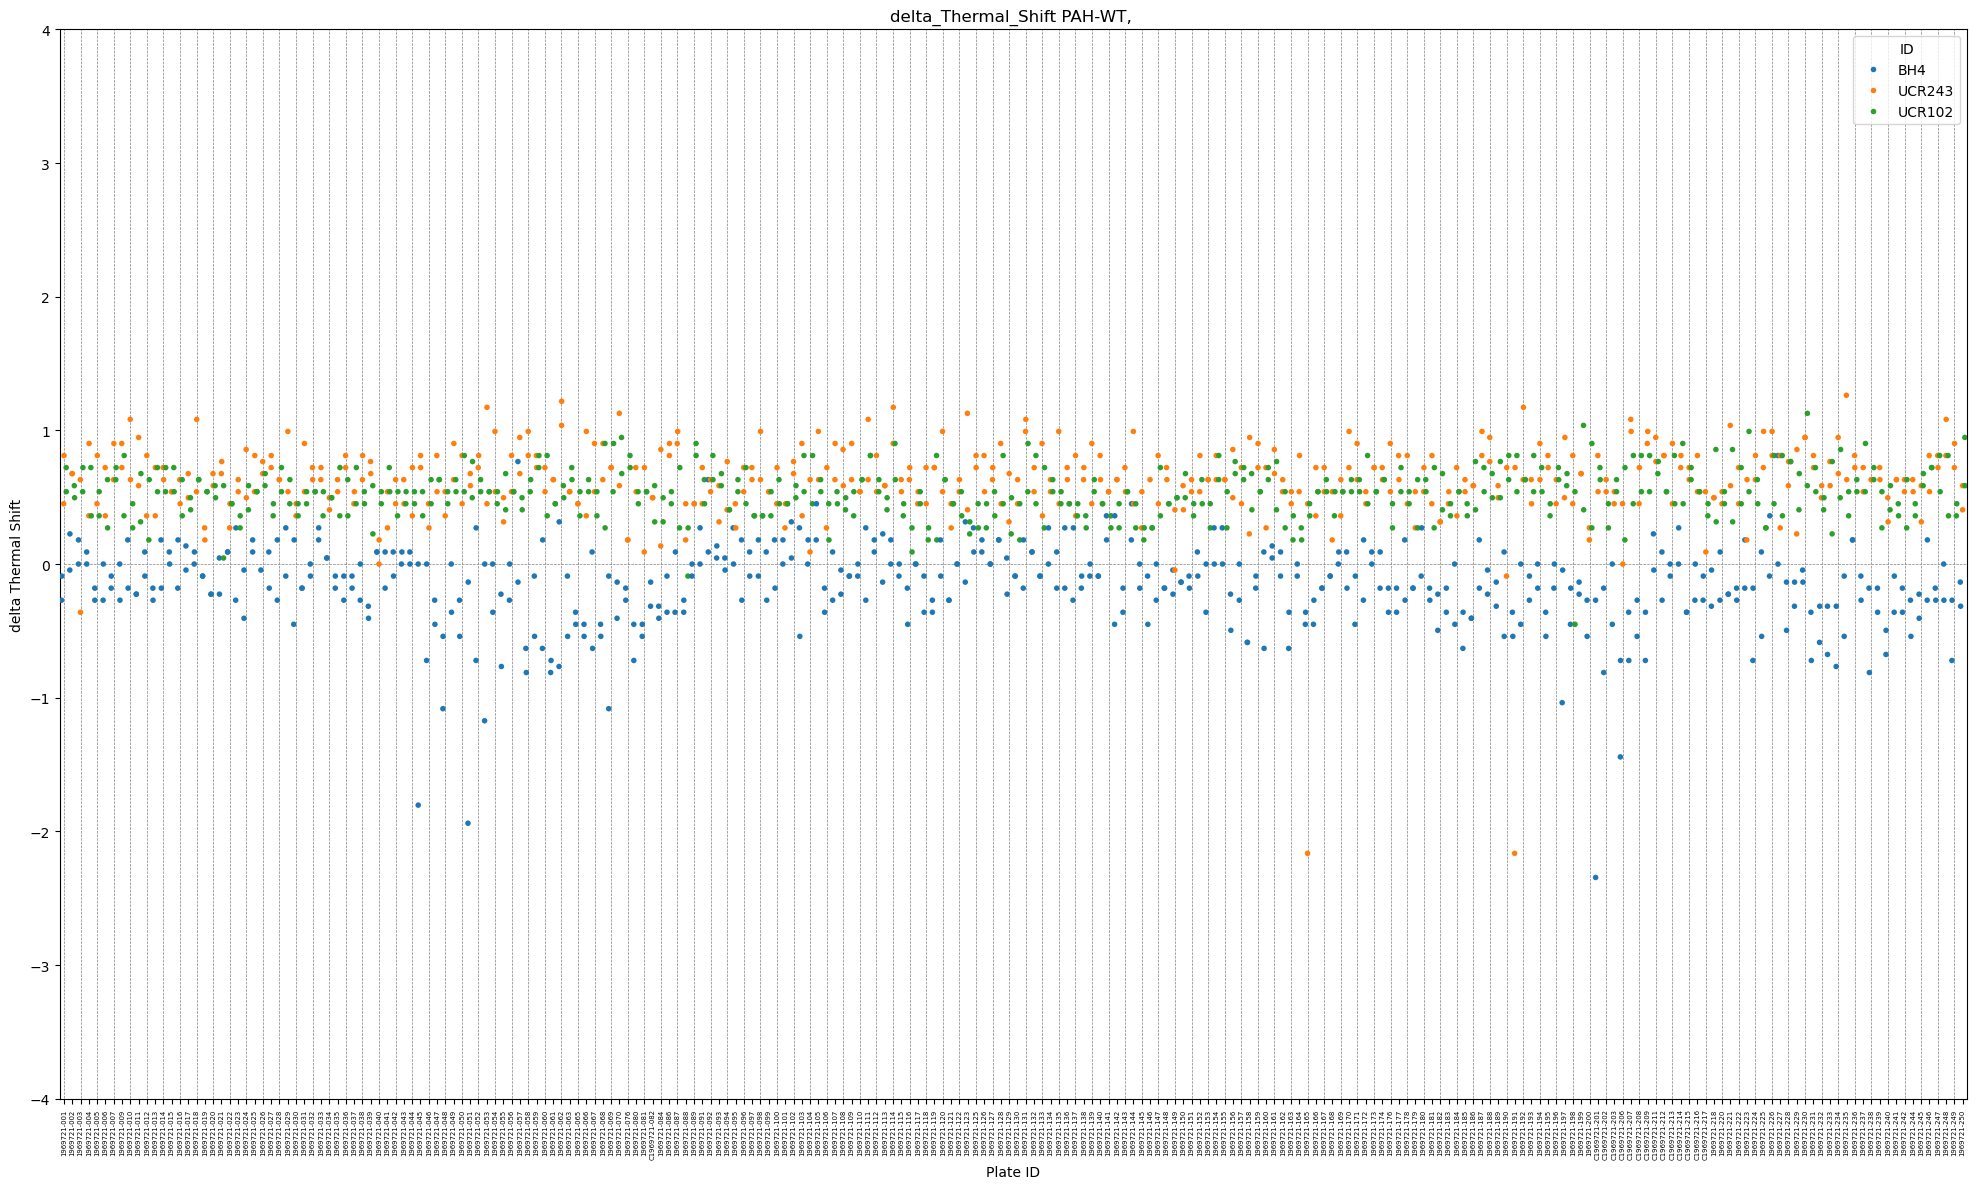

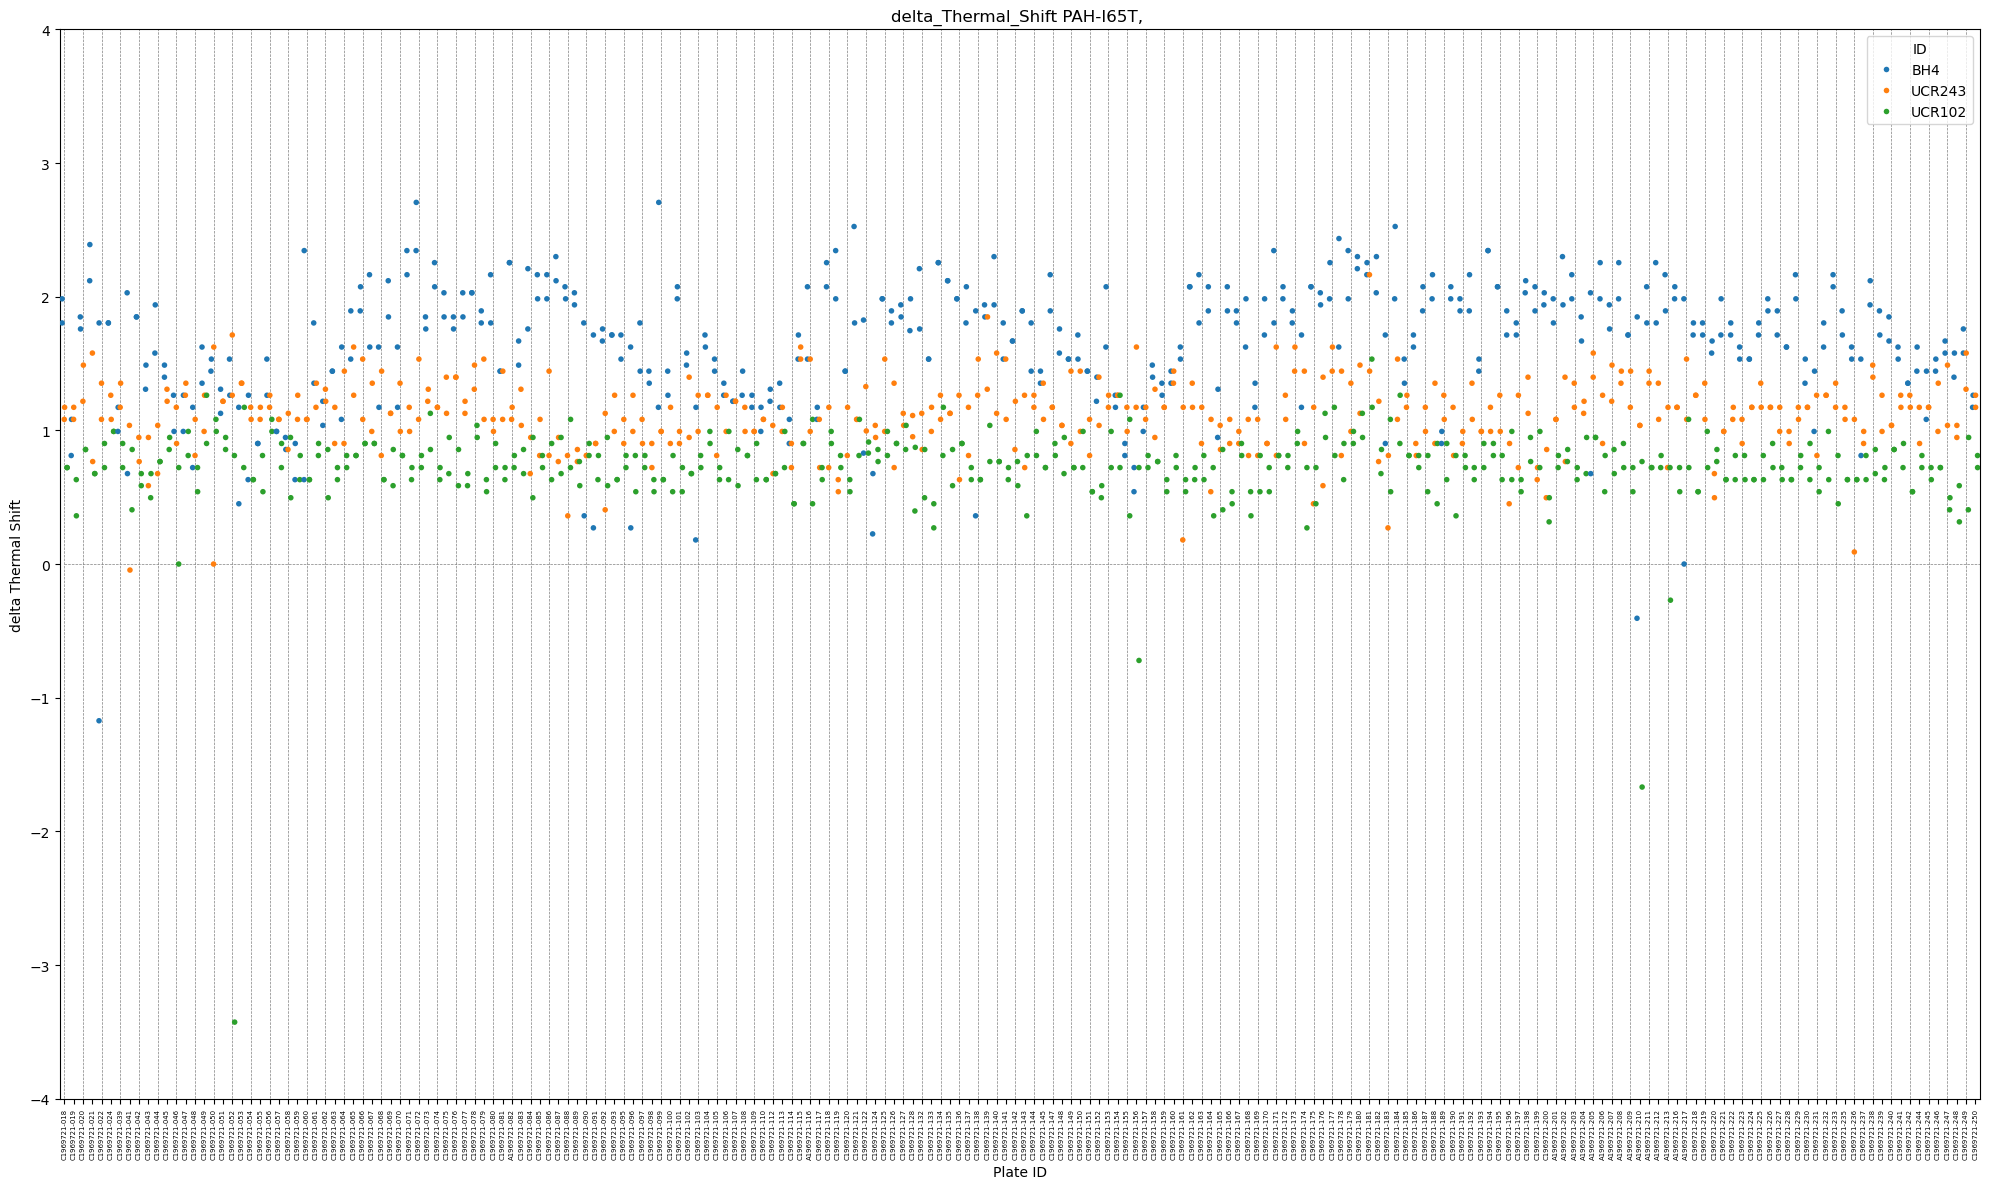

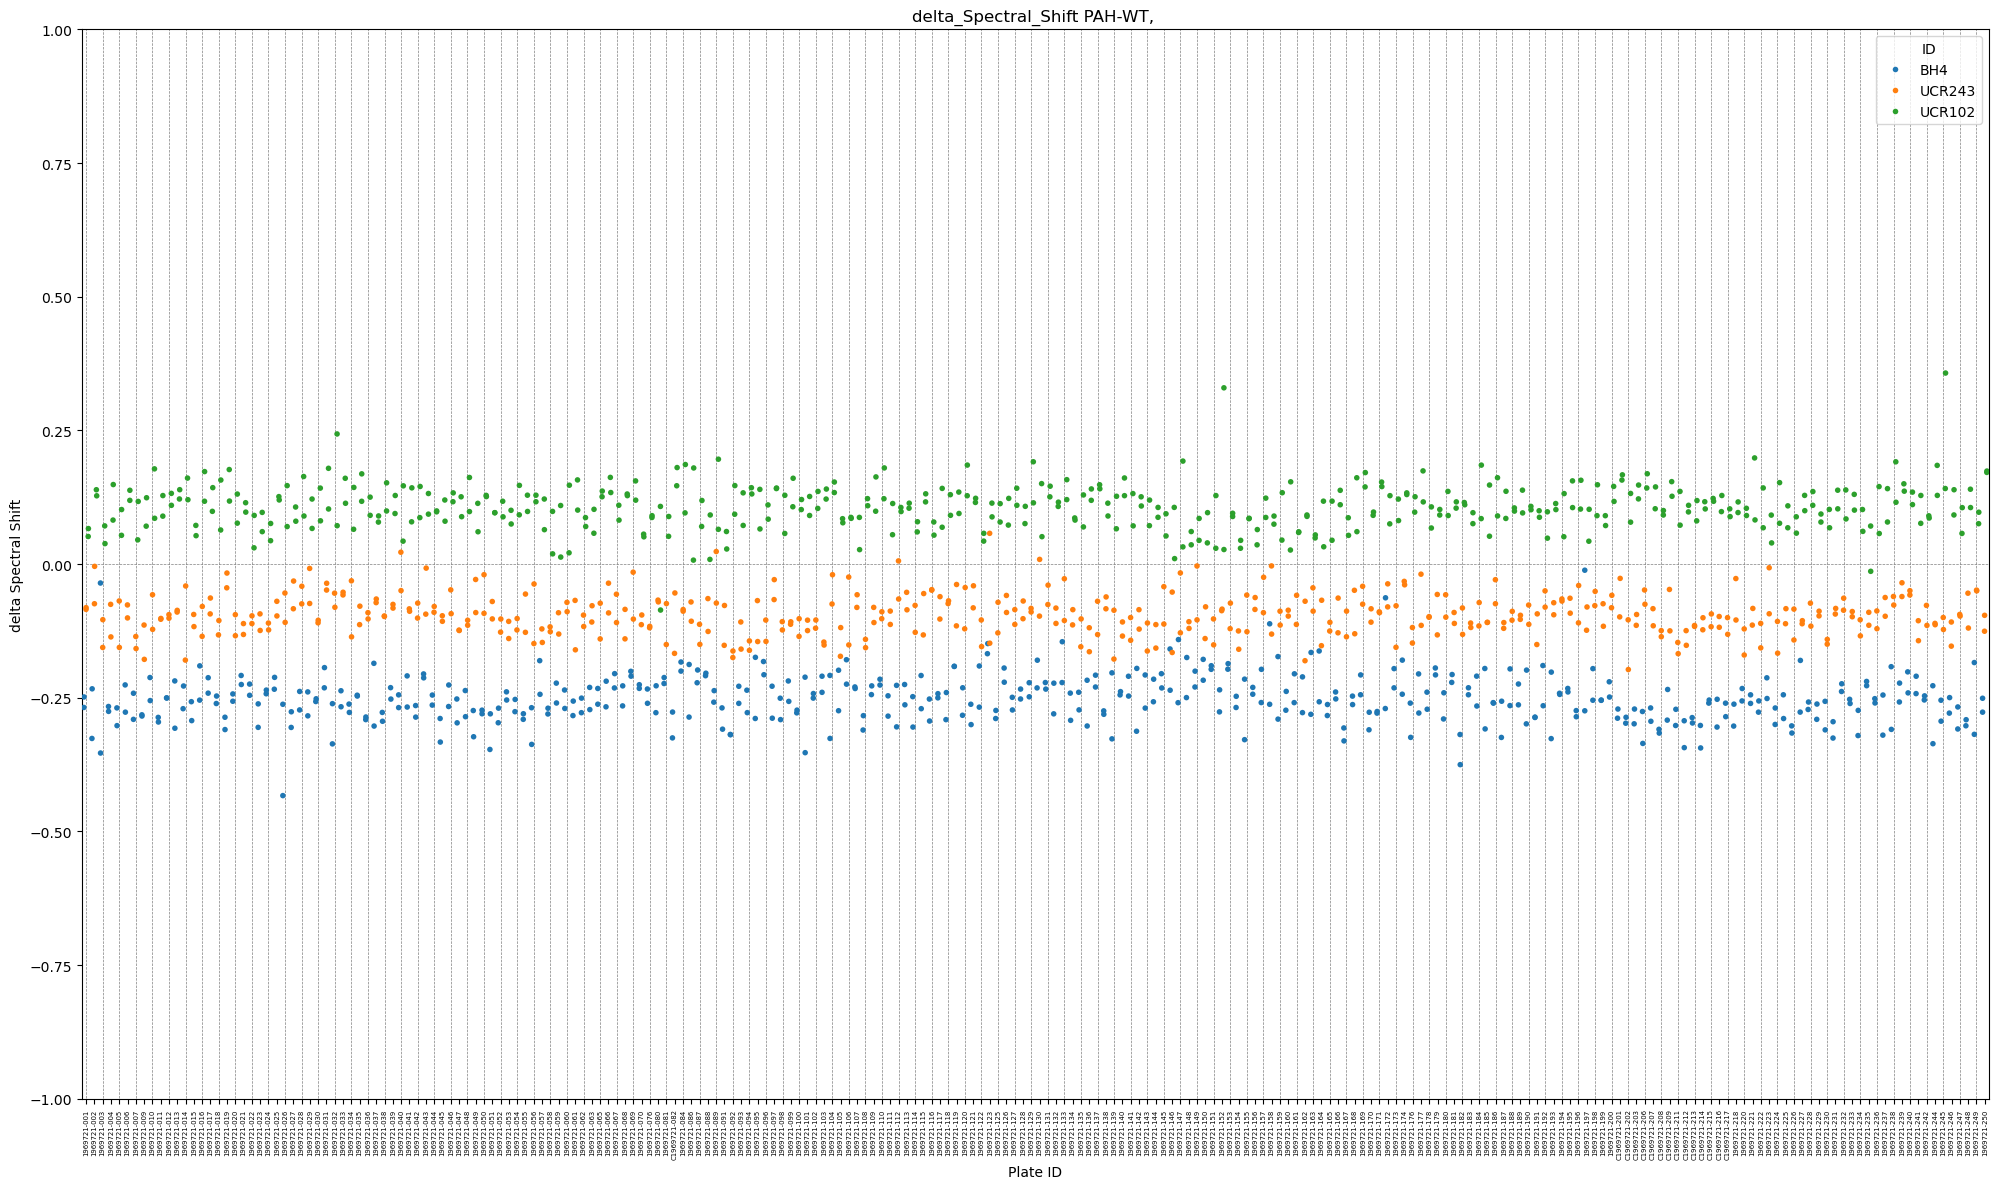

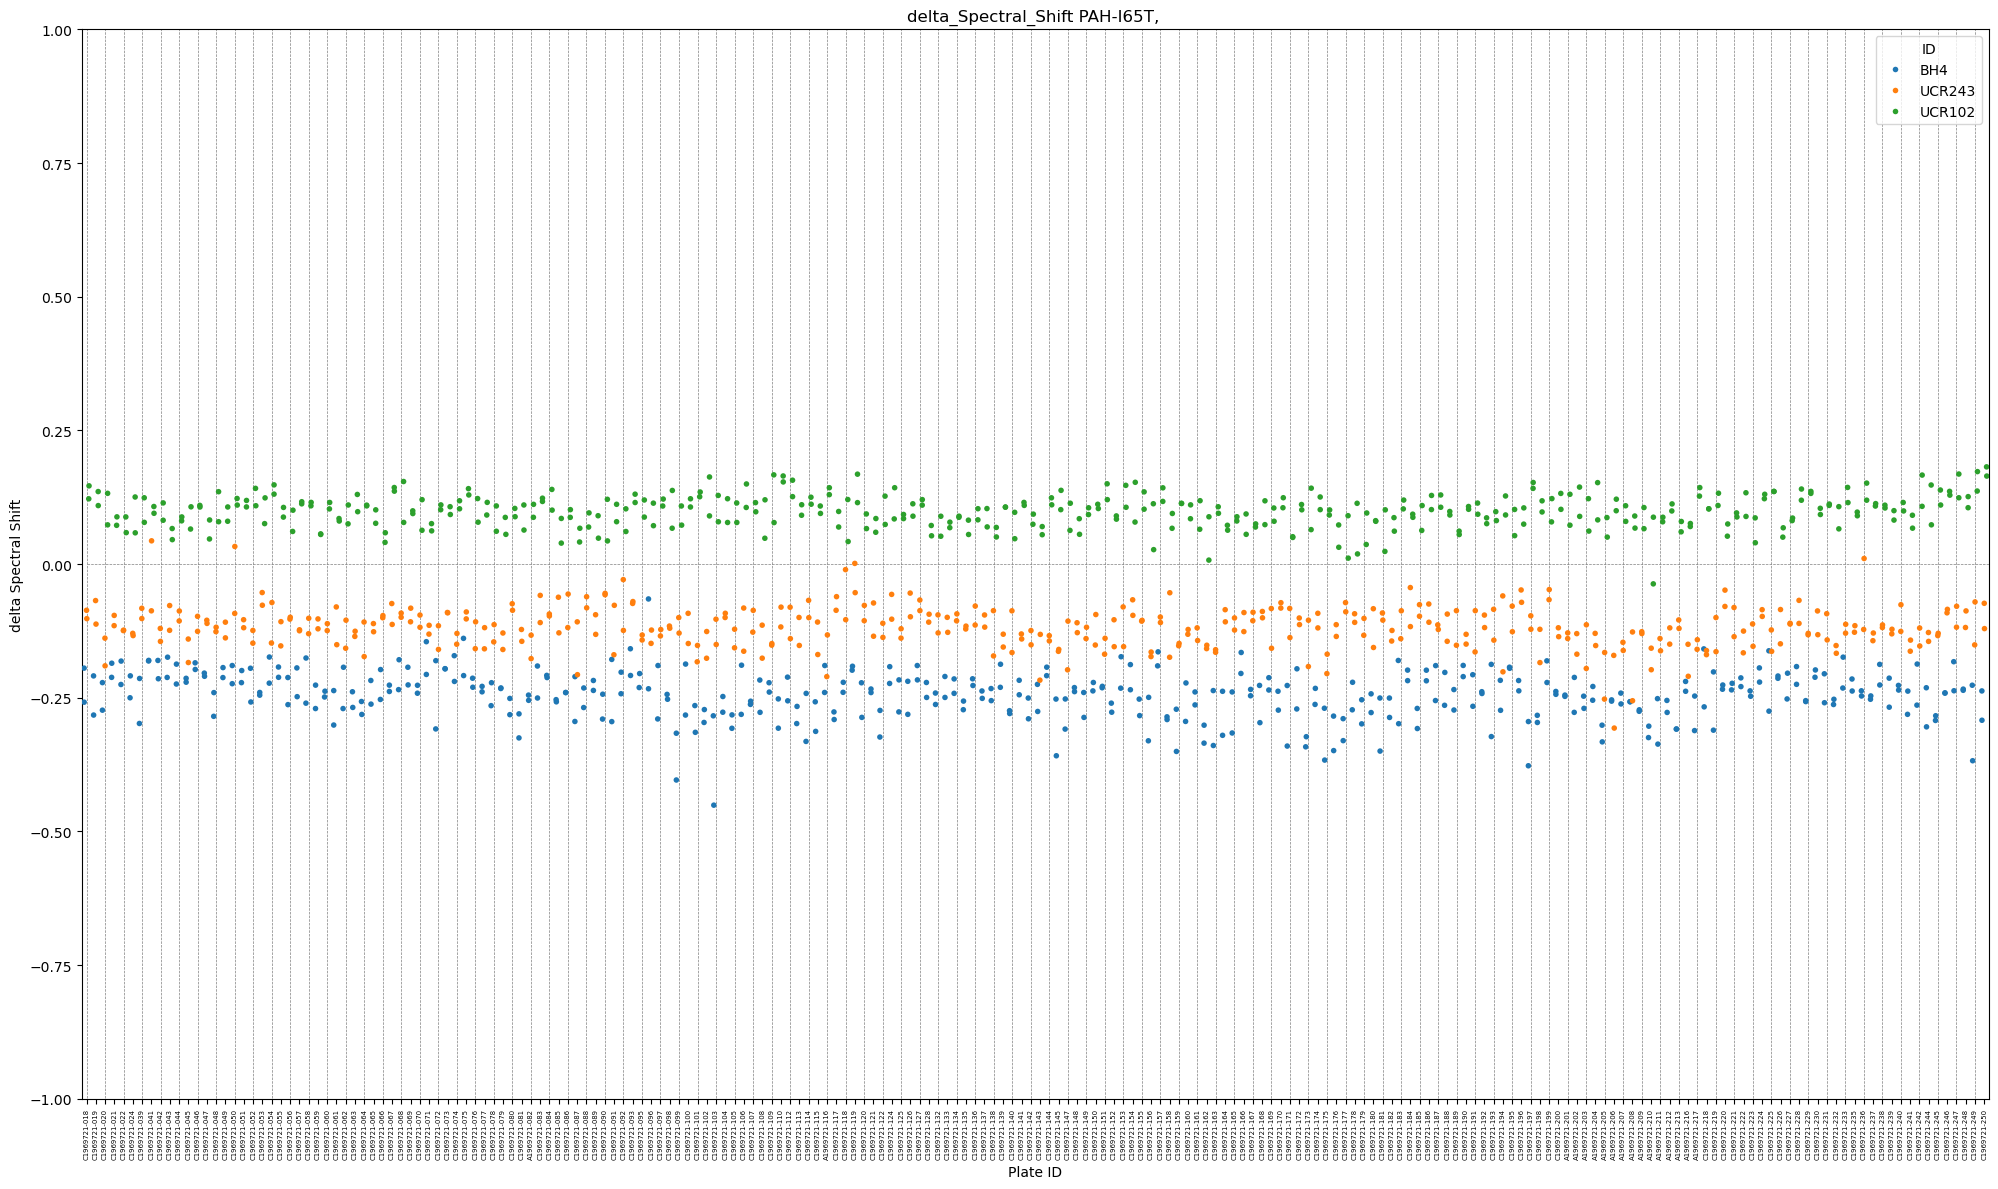

In [163]:
# Plot positive controls
# Make categorical plate ids with sorted levels based on numbers
df_plate_ids = pd.DataFrame({'ids' : df_other['Plate_ID'].unique()})
df_plate_ids['ids_no_letter'] = [i[1:] if i[0].isalpha() else i for i in df_plate_ids['ids']]
df_plate_ids = df_plate_ids.sort_values('ids_no_letter')
df_plate = df_plate_ids['ids']
df_other['Plate_ID_cat'] = pd.Categorical(df_other['Plate_ID'], categories=df_plate, ordered=True)

dotplot_per_plate(df_other, 
                  assay = 'delta_Thermal_Shift', 
                  protein = 'PAH-WT', 
                  ids = ['BH4', 'UCR243', 'UCR102'],
                  ylim=[-4, 4]
                 )

dotplot_per_plate(df_other, 
                  assay = 'delta_Thermal_Shift', 
                  protein = 'PAH-I65T', 
                  ids = ['BH4', 'UCR243', 'UCR102'],
                  ylim=[-4, 4]
                 )

dotplot_per_plate(df_other, 
                  assay = 'delta_Spectral_Shift', 
                  protein = 'PAH-WT', 
                  ids = ['BH4', 'UCR243', 'UCR102'],
                  ylim=[-1, 1]
                 )

dotplot_per_plate(df_other, 
                  assay = 'delta_Spectral_Shift', 
                  protein = 'PAH-I65T', 
                  ids = ['BH4', 'UCR243', 'UCR102'],
                  ylim=[-1, 1]
                 )

In [6]:
df_other_wt = df_other.loc[df_other['Protein'] == 'PAH-WT']
df_other_mut = df_other.loc[df_other['Protein'] == 'PAH-I65T']
df_ctrl_wt = df_ctrl.loc[df_ctrl['Protein'] == 'PAH-WT']
df_ctrl_mut = df_ctrl.loc[df_ctrl['Protein'] == 'PAH-I65T']

## Normality test

/Users/behnam/miniconda3/envs/chem/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: Input data has range zero. The results may not be accurate.
  res = hypotest_fun_out(*samples, **kwds)


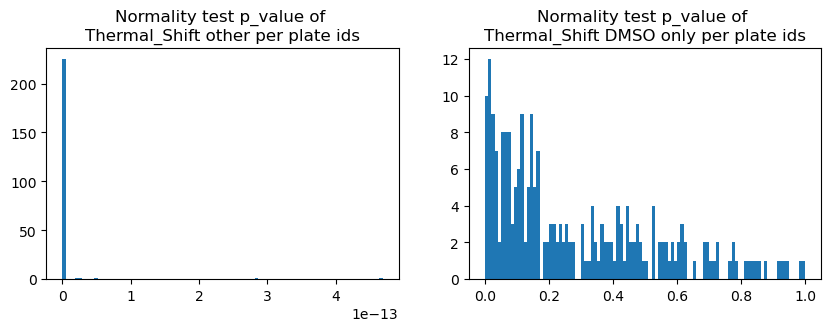

In [7]:
assay = 'Thermal_Shift'

norm_p_all = []
norm_p_ctrl = []
for i in df_other_wt['Plate_ID'].unique():
    x = df_other_wt.loc[df_other_wt['Plate_ID'] == i, assay]
    stat, p = stats.shapiro(x)
    norm_p_all.append(p)
    x = df_ctrl_wt.loc[df_ctrl_wt['Plate_ID'] == i, assay]
    stat, p = stats.shapiro(x)
    norm_p_ctrl.append(p)

norm_p_all = np.array(norm_p_all)
norm_p_ctrl = np.array(norm_p_ctrl)

fig, ax = plt.subplots(1, 2, figsize=(10,3))
ax[0].hist(norm_p_all, 100);
ax[1].hist(norm_p_ctrl, 100);
ax[0].set_title(f'Normality test p_value of \n{assay} other per plate ids');
ax[1].set_title(f'Normality test p_value of \n{assay} DMSO only per plate ids');

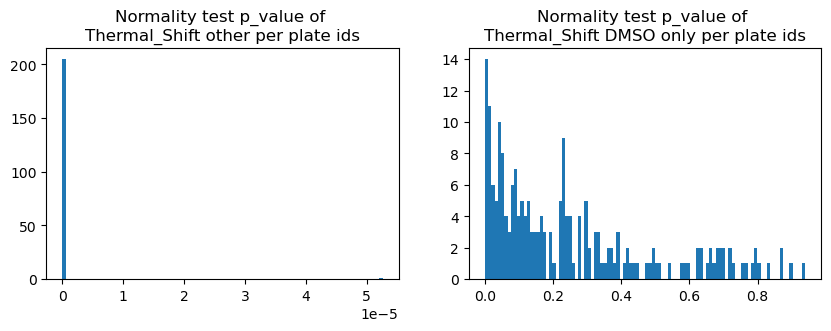

In [8]:
assay = 'Thermal_Shift'

norm_p_all = []
norm_p_ctrl = []
for i in df_other_mut['Plate_ID'].unique():
    x = df_other_mut.loc[df_other_mut['Plate_ID'] == i, assay]
    stat, p = stats.shapiro(x)
    norm_p_all.append(p)
    x = df_ctrl_mut.loc[df_ctrl_mut['Plate_ID'] == i, assay]
    stat, p = stats.shapiro(x)
    norm_p_ctrl.append(p)

norm_p_all = np.array(norm_p_all)
norm_p_ctrl = np.array(norm_p_ctrl)

fig, ax = plt.subplots(1, 2, figsize=(10,3))
ax[0].hist(norm_p_all, 100);
ax[1].hist(norm_p_ctrl, 100);
ax[0].set_title(f'Normality test p_value of \n{assay} other per plate ids');
ax[1].set_title(f'Normality test p_value of \n{assay} DMSO only per plate ids');

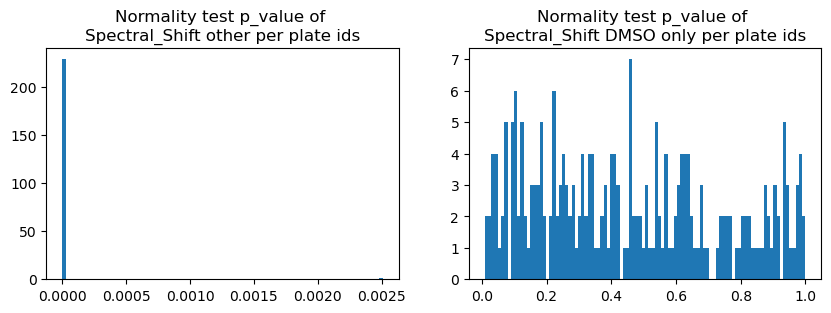

In [9]:
assay = 'Spectral_Shift'

norm_p_all = []
norm_p_ctrl = []
for i in df_other_wt['Plate_ID'].unique():
    x = df_other_wt.loc[df_other_wt['Plate_ID'] == i, assay]
    stat, p = stats.shapiro(x)
    norm_p_all.append(p)
    x = df_ctrl_wt.loc[df_ctrl_wt['Plate_ID'] == i, assay]
    stat, p = stats.shapiro(x)
    norm_p_ctrl.append(p)

norm_p_all = np.array(norm_p_all)
norm_p_ctrl = np.array(norm_p_ctrl)

fig, ax = plt.subplots(1, 2, figsize=(10,3))
ax[0].hist(norm_p_all, 100);
ax[1].hist(norm_p_ctrl, 100);
ax[0].set_title(f'Normality test p_value of \n{assay} other per plate ids');
ax[1].set_title(f'Normality test p_value of \n{assay} DMSO only per plate ids');

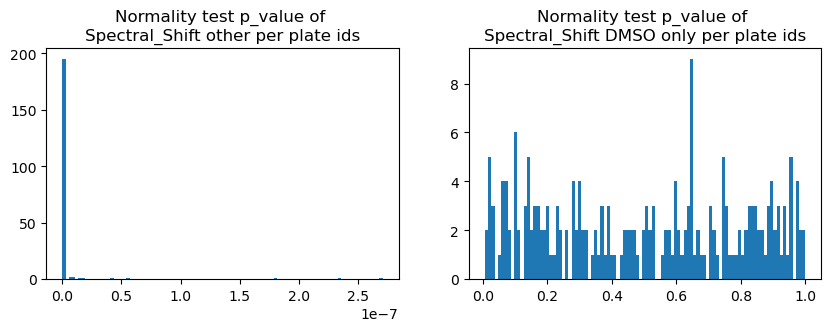

In [10]:
assay = 'Spectral_Shift'

norm_p_all = []
norm_p_ctrl = []
for i in df_other_mut['Plate_ID'].unique():
    x = df_other_mut.loc[df_other_mut['Plate_ID'] == i, assay]
    stat, p = stats.shapiro(x)
    norm_p_all.append(p)
    x = df_ctrl_mut.loc[df_ctrl_mut['Plate_ID'] == i, assay]
    stat, p = stats.shapiro(x)
    norm_p_ctrl.append(p)

norm_p_all = np.array(norm_p_all)
norm_p_ctrl = np.array(norm_p_ctrl)

fig, ax = plt.subplots(1, 2, figsize=(10,3))
ax[0].hist(norm_p_all, 100);
ax[1].hist(norm_p_ctrl, 100);
ax[0].set_title(f'Normality test p_value of \n{assay} other per plate ids');
ax[1].set_title(f'Normality test p_value of \n{assay} DMSO only per plate ids');

## Emperical test

100%|████████████████████████████████| 142136/142136 [00:07<00:00, 18062.15it/s]


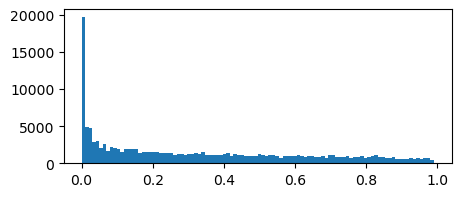

In [11]:
# Spectral_Shift p-value
assay = 'Spectral_Shift'

# Calculate p-values
df_other['SpSh_pval'] = np.nan

null_wt = df_ctrl_wt[f'delta_{assay}'].values
null_mut = df_ctrl_mut[f'delta_{assay}'].values

for i in tqdm(df_other.index):
    x = df_other.loc[i, f'delta_{assay}']
    
    protein = df_other.loc[i, 'Protein']
    null = null_wt if protein == 'PAH-WT' else null_mut
    
    p = emperical_p_value(x, null, alternative='greater', take_abs=True)
    df_other.loc[i, 'SpSh_pval'] = p

plt.figure(figsize=(5, 2))
plt.hist(df_other['SpSh_pval'], 100);

In [12]:
# Correct for multiple testting
df_other['SpSh_qval'] = 1.
_, df_other.loc[df_other['Protein'] == 'PAH-WT', 'SpSh_qval'], _, _ = multipletests(df_other.loc[df_other['Protein'] == 'PAH-WT', 'SpSh_pval'], method='fdr_bh')
_, df_other.loc[df_other['Protein'] == 'PAH-I65T', 'SpSh_qval'], _, _ = multipletests(df_other.loc[df_other['Protein'] == 'PAH-I65T', 'SpSh_pval'], method='fdr_bh')
# _, df_other['SpSh_qval'], _, _ = multipletests(df_other['SpSh_pval'], method='fdr_bh')


df_other['bind_pval'] = df_other['SpSh_pval'] < .05
df_other['bind_qval'] = df_other['SpSh_qval'] < .015

In [13]:
df_other['bind_combined'] = 'weak_evidence'
df_other.loc[df_other['bind_qval'], 'bind_combined'] = 'strong_evidence'
df_other.loc[~df_other['bind_pval'], 'bind_combined'] = 'no_evidence'

In [14]:
df_other.loc[df_other['Protein'] == 'PAH-I65T', 'SpSh_qval'].min()

np.float64(0.01170369892724226)

In [15]:
# Filter out specific IDs
filtered_df = df_other.loc[(df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])) & (df_other['Protein'] == 'PAH-WT')]

summary_table = pd.pivot_table(
    filtered_df,
    index='ID',
    columns='bind_combined',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table[['no_evidence', 'weak_evidence', 'strong_evidence', 'Total']]

bind_combined,no_evidence,weak_evidence,strong_evidence,Total
ID,,,,
BH4,3,15,442,460
UCR102,69,378,13,460
UCR243,92,366,2,460
Total,164,759,457,1380


In [16]:
# Filter out specific IDs
filtered_df = df_other.loc[(df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])) & (df_other['Protein'] == 'PAH-I65T')]

summary_table = pd.pivot_table(
    filtered_df,
    index='ID',
    columns='bind_combined',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table[['no_evidence', 'weak_evidence', 'strong_evidence', 'Total']]

bind_combined,no_evidence,weak_evidence,strong_evidence,Total
ID,,,,
BH4,NaN,3.0,409.0,412
UCR102,24.0,372.0,16.0,412
UCR243,10.0,327.0,75.0,412
Total,34.0,702.0,500.0,1236


In [17]:
s1 = set(df_other.loc[(df_other['Protein'] == 'PAH-WT') & (df_other['bind_qval']), 'ID'].unique())
s2 = set(df_other.loc[(df_other['Protein'] == 'PAH-I65T') & (df_other['bind_qval']), 'ID'].unique())
len(s1.intersection(s2))

633

100%|████████████████████████████████| 142136/142136 [00:14<00:00, 10030.22it/s]


Text(0.5, 1.0, 'TSA_pval_destabilizer')

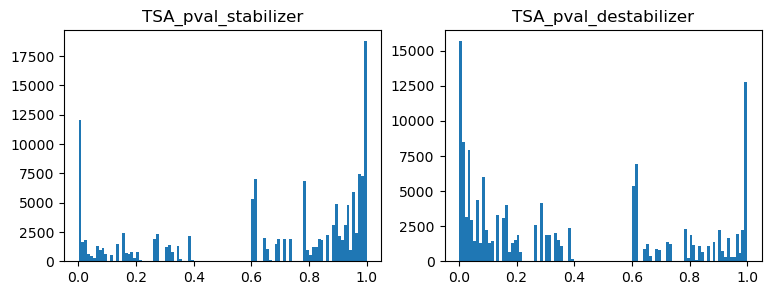

In [18]:
assay = 'Thermal_Shift'

df_other['TSA_pval_stabilizer'] = np.nan
df_other['TSA_pval_destabilizer'] = np.nan

null_wt = df_ctrl_wt[f'delta_{assay}'].values
null_mut = df_ctrl_mut[f'delta_{assay}'].values

for i in tqdm(df_other.index):
    x = df_other.loc[i, f'delta_{assay}']

    protein = df_other.loc[i, 'Protein']
    null = null_wt if protein == 'PAH-WT' else null_mut
    
    p = emperical_p_value(x, null, alternative='greater', take_abs=False)
    df_other.loc[i, 'TSA_pval_stabilizer'] = p
    p = emperical_p_value(x, null, alternative='less', take_abs=False)
    df_other.loc[i, 'TSA_pval_destabilizer'] = p

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(df_other['TSA_pval_stabilizer'], 100);
ax[0].set_title('TSA_pval_stabilizer')
ax[1].hist(df_other['TSA_pval_destabilizer'], 100);
ax[1].set_title('TSA_pval_destabilizer')

# This descretness is due to the use of median subtraction instead of mean subtraction and the descrete nature of the TSA

In [19]:
df_other['TSA_qval_stabilizer'] = 1.
df_other['TSA_qval_destabilizer'] = 1.
_, df_other.loc[df_other['Protein'] == 'PAH-WT', 'TSA_qval_stabilizer'], _, _ = multipletests(df_other.loc[df_other['Protein'] == 'PAH-WT', 'TSA_pval_stabilizer'], method='fdr_bh')
_, df_other.loc[df_other['Protein'] == 'PAH-I65T', 'TSA_qval_stabilizer'], _, _ = multipletests(df_other.loc[df_other['Protein'] == 'PAH-I65T', 'TSA_pval_stabilizer'], method='fdr_bh')
_, df_other.loc[df_other['Protein'] == 'PAH-WT', 'TSA_qval_destabilizer'], _, _ = multipletests(df_other.loc[df_other['Protein'] == 'PAH-WT', 'TSA_pval_destabilizer'], method='fdr_bh')
_, df_other.loc[df_other['Protein'] == 'PAH-I65T', 'TSA_qval_destabilizer'], _, _ = multipletests(df_other.loc[df_other['Protein'] == 'PAH-I65T', 'TSA_pval_destabilizer'], method='fdr_bh')

df_other['stabilize_pval'] = df_other['TSA_pval_stabilizer'] < .05
df_other['stabilize_qval'] = df_other['TSA_qval_stabilizer'] < .015
df_other['destabilize_pval'] = df_other['TSA_pval_destabilizer'] < .05
df_other['destabilize_qval'] = df_other['TSA_qval_destabilizer'] < .015

In [20]:
df_other['stabilize_combined'] = 'weak_evidence'
df_other.loc[df_other['stabilize_qval'], 'stabilize_combined'] = 'strong_evidence'
df_other.loc[~df_other['stabilize_pval'], 'stabilize_combined'] = 'no_evidence'

df_other['destabilize_combined'] = 'weak_evidence'
df_other.loc[df_other['destabilize_qval'], 'destabilize_combined'] = 'strong_evidence'
df_other.loc[~df_other['destabilize_pval'], 'destabilize_combined'] = 'no_evidence'

In [21]:
# Filter out specific IDs
filtered_df = df_other.loc[df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])]

summary_table = pd.pivot_table(
    filtered_df,
    index='ID',
    columns='stabilize_combined',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table[['no_evidence', 'weak_evidence', 'strong_evidence', 'Total']]

stabilize_combined,no_evidence,weak_evidence,strong_evidence,Total
ID,,,,
BH4,454,19,399,872
UCR102,55,415,402,872
UCR243,40,178,654,872
Total,549,612,1455,2616


In [22]:
# Filter out specific IDs
filtered_df = df_other.loc[df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])]

summary_table = pd.pivot_table(
    filtered_df,
    index='ID',
    columns='destabilize_combined',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table[['no_evidence', 'weak_evidence', 'strong_evidence', 'Total']]

destabilize_combined,no_evidence,weak_evidence,strong_evidence,Total
ID,,,,
BH4,753.0,111.0,8.0,872
UCR102,868.0,4.0,NaN,872
UCR243,868.0,1.0,3.0,872
Total,2489.0,116.0,11.0,2616


In [23]:
# Filter out controls
filtered_df = df_other.loc[~df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])]

summary_table = pd.pivot_table(
    filtered_df,
    index='ID',
    columns='destabilize_combined',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table[['no_evidence', 'weak_evidence', 'strong_evidence', 'Total']]

destabilize_combined,no_evidence,weak_evidence,strong_evidence,Total
ID,,,,
CSCS00000000223,2.0,NaN,NaN,2
CSCS00000001360,1.0,1.0,NaN,2
CSCS00000002033,2.0,NaN,NaN,2
CSCS00000002216,2.0,NaN,NaN,2
CSCS00000002301,2.0,NaN,NaN,2
...,...,...,...,...
CSCS00133154406,NaN,1.0,NaN,1
CSCS00133154427,1.0,NaN,1.0,2
CSCS00133154429,2.0,NaN,NaN,2


In [131]:
## Add Binding_validated_by_TSA
conversion_dict_bind = {
    ('strong_evidence', 'strong_evidence', 'strong_evidence') : 'strong_evidence',
    ('strong_evidence', 'strong_evidence', 'weak_evidence')   : 'strong_evidence',
    ('strong_evidence', 'strong_evidence', 'no_evidence')     : 'strong_evidence',
    ('strong_evidence', 'weak_evidence',   'strong_evidence') : 'strong_evidence',
    ('strong_evidence', 'weak_evidence',   'weak_evidence')   : 'strong_evidence',
    ('strong_evidence', 'weak_evidence',   'no_evidence')     : 'strong_evidence',
    ('strong_evidence', 'no_evidence',     'strong_evidence') : 'strong_evidence',
    ('strong_evidence', 'no_evidence',     'weak_evidence')   : 'strong_evidence',
    ('strong_evidence', 'no_evidence',     'no_evidence')     : 'weak_evidence',
    ('weak_evidence',   'strong_evidence', 'strong_evidence') : 'weak_evidence',
    ('weak_evidence',   'strong_evidence', 'weak_evidence')   : 'weak_evidence',
    ('weak_evidence',   'strong_evidence', 'no_evidence')     : 'strong_evidence',
    ('weak_evidence',   'weak_evidence',   'strong_evidence') : 'weak_evidence',
    ('weak_evidence',   'weak_evidence',   'weak_evidence')   : 'weak_evidence',
    ('weak_evidence',   'weak_evidence',   'no_evidence')     : 'weak_evidence',
    ('weak_evidence',   'no_evidence',     'strong_evidence') : 'strong_evidence',
    ('weak_evidence',   'no_evidence',     'weak_evidence')   : 'weak_evidence',
    ('weak_evidence',   'no_evidence',     'no_evidence')     : 'weak_evidence',
    ('no_evidence',     'strong_evidence', 'strong_evidence') : 'weak_evidence',
    ('no_evidence',     'strong_evidence', 'weak_evidence')   : 'weak_evidence',
    ('no_evidence',     'strong_evidence', 'no_evidence')     : 'weak_evidence',
    ('no_evidence',     'weak_evidence',   'strong_evidence') : 'weak_evidence',
    ('no_evidence',     'weak_evidence',   'weak_evidence')   : 'weak_evidence',
    ('no_evidence',     'weak_evidence',   'no_evidence')     : 'weak_evidence',
    ('no_evidence',     'no_evidence',     'strong_evidence') : 'weak_evidence',
    ('no_evidence',     'no_evidence',     'weak_evidence')   : 'weak_evidence',
    ('no_evidence',     'no_evidence',     'no_evidence')     : 'no_evidence',
}

## Add stablize_and_bind
conversion_dict_stablize = {
    ('strong_evidence', 'strong_evidence', 'strong_evidence') : 'no_evidence',
    ('strong_evidence', 'strong_evidence', 'weak_evidence')   : 'no_evidence',
    ('strong_evidence', 'strong_evidence', 'no_evidence')     : 'strong_evidence',
    ('strong_evidence', 'weak_evidence',   'strong_evidence') : 'no_evidence',
    ('strong_evidence', 'weak_evidence',   'weak_evidence')   : 'no_evidence',
    ('strong_evidence', 'weak_evidence',   'no_evidence')     : 'no_evidence',
    ('strong_evidence', 'no_evidence',     'strong_evidence') : 'no_evidence',
    ('strong_evidence', 'no_evidence',     'weak_evidence')   : 'no_evidence',
    ('strong_evidence', 'no_evidence',     'no_evidence')     : 'no_evidence',
    ('weak_evidence',   'strong_evidence', 'strong_evidence') : 'no_evidence',
    ('weak_evidence',   'strong_evidence', 'weak_evidence')   : 'no_evidence',
    ('weak_evidence',   'strong_evidence', 'no_evidence')     : 'weak_evidence',
    ('weak_evidence',   'weak_evidence',   'strong_evidence') : 'no_evidence',
    ('weak_evidence',   'weak_evidence',   'weak_evidence')   : 'no_evidence',
    ('weak_evidence',   'weak_evidence',   'no_evidence')     : 'no_evidence',
    ('weak_evidence',   'no_evidence',     'strong_evidence') : 'no_evidence',
    ('weak_evidence',   'no_evidence',     'weak_evidence')   : 'no_evidence',
    ('weak_evidence',   'no_evidence',     'no_evidence')     : 'no_evidence',
    ('no_evidence',     'strong_evidence', 'strong_evidence') : 'no_evidence',
    ('no_evidence',     'strong_evidence', 'weak_evidence')   : 'no_evidence',
    ('no_evidence',     'strong_evidence', 'no_evidence')     : 'no_evidence',
    ('no_evidence',     'weak_evidence',   'strong_evidence') : 'no_evidence',
    ('no_evidence',     'weak_evidence',   'weak_evidence')   : 'no_evidence',
    ('no_evidence',     'weak_evidence',   'no_evidence')     : 'no_evidence',
    ('no_evidence',     'no_evidence',     'strong_evidence') : 'no_evidence',
    ('no_evidence',     'no_evidence',     'weak_evidence')   : 'no_evidence',
    ('no_evidence',     'no_evidence',     'no_evidence')     : 'no_evidence',
}


## Add groups
conversion_dict_group = {
    ('strong_evidence', 'strong_evidence', 'strong_evidence') : 'group1',
    ('strong_evidence', 'strong_evidence', 'weak_evidence')   : 'group2',
    ('strong_evidence', 'strong_evidence', 'no_evidence')     : 'group3',
    ('strong_evidence', 'weak_evidence',   'strong_evidence') : 'group4',
    ('strong_evidence', 'weak_evidence',   'weak_evidence')   : 'group5',
    ('strong_evidence', 'weak_evidence',   'no_evidence')     : 'group6',
    ('strong_evidence', 'no_evidence',     'strong_evidence') : 'group0',
    ('strong_evidence', 'no_evidence',     'weak_evidence')   : 'group0',
    ('strong_evidence', 'no_evidence',     'no_evidence')     : 'group7',
    ('weak_evidence',   'strong_evidence', 'strong_evidence') : 'group0',
    ('weak_evidence',   'strong_evidence', 'weak_evidence')   : 'group0',
    ('weak_evidence',   'strong_evidence', 'no_evidence')     : 'group0',
    ('weak_evidence',   'weak_evidence',   'strong_evidence') : 'group0',
    ('weak_evidence',   'weak_evidence',   'weak_evidence')   : 'group0',
    ('weak_evidence',   'weak_evidence',   'no_evidence')     : 'group0',
    ('weak_evidence',   'no_evidence',     'strong_evidence') : 'group0',
    ('weak_evidence',   'no_evidence',     'weak_evidence')   : 'group0',
    ('weak_evidence',   'no_evidence',     'no_evidence')     : 'group0',
    ('no_evidence',     'strong_evidence', 'strong_evidence') : 'group0',
    ('no_evidence',     'strong_evidence', 'weak_evidence')   : 'group0',
    ('no_evidence',     'strong_evidence', 'no_evidence')     : 'group0',
    ('no_evidence',     'weak_evidence',   'strong_evidence') : 'group0',
    ('no_evidence',     'weak_evidence',   'weak_evidence')   : 'group0',
    ('no_evidence',     'weak_evidence',   'no_evidence')     : 'group0',
    ('no_evidence',     'no_evidence',     'strong_evidence') : 'group0',
    ('no_evidence',     'no_evidence',     'weak_evidence')   : 'group0',
    ('no_evidence',     'no_evidence',     'no_evidence')     : 'group0',
}

In [132]:
# Add a new column bind_tsa
bind_tsa = [(i, j, k) for i, j, k in zip(
    df_other['bind_combined'], 
    df_other['stabilize_combined'], 
    df_other['destabilize_combined']
)]
df_other['bind_tsa'] = bind_tsa
df_other['bind_tsa'] = pd.Categorical(df_other['bind_tsa'], categories=list(conversion_dict_bind.keys()), ordered=True)

In [133]:
# Filter specific IDs
filtered_df = df_other.loc[(df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])) & (df_other['Protein'] == 'PAH-WT')]

summary_table = pd.pivot_table(
    filtered_df,
    index='bind_tsa',
    columns='ID',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table

/var/folders/g9/1n3d85nn2d14mq2r60k26ddc0000gn/T/ipykernel_27028/130134969.py:4: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  summary_table = pd.pivot_table(


ID,BH4,UCR102,UCR243,Total
bind_tsa,,,,
"(strong_evidence, strong_evidence, strong_evidence)",0,0,0,NaN
"(strong_evidence, strong_evidence, weak_evidence)",0,0,0,NaN
"(strong_evidence, strong_evidence, no_evidence)",4,4,1,9.0
"(strong_evidence, weak_evidence, strong_evidence)",0,0,0,NaN
"(strong_evidence, weak_evidence, weak_evidence)",0,0,0,NaN
"(strong_evidence, weak_evidence, no_evidence)",7,9,1,17.0
"(strong_evidence, no_evidence, strong_evidence)",7,0,0,7.0
"(strong_evidence, no_evidence, weak_evidence)",106,0,0,106.0
"(strong_evidence, no_evidence, no_evidence)",318,0,0,318.0


In [134]:
# Filter out specific IDs
filtered_df = df_other.loc[(df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])) & (df_other['Protein'] == 'PAH-I65T')]

summary_table = pd.pivot_table(
    filtered_df,
    index='bind_tsa',
    columns='ID',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table#[['no_evidence', 'weak_evidence', 'strong_evidence', 'Total']]

/var/folders/g9/1n3d85nn2d14mq2r60k26ddc0000gn/T/ipykernel_27028/3243618149.py:4: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  summary_table = pd.pivot_table(


ID,BH4,UCR102,UCR243,Total
bind_tsa,,,,
"(strong_evidence, strong_evidence, strong_evidence)",0,0,0,NaN
"(strong_evidence, strong_evidence, weak_evidence)",0,0,0,NaN
"(strong_evidence, strong_evidence, no_evidence)",393,6,74,473.0
"(strong_evidence, weak_evidence, strong_evidence)",0,0,0,NaN
"(strong_evidence, weak_evidence, weak_evidence)",0,0,0,NaN
"(strong_evidence, weak_evidence, no_evidence)",11,10,1,22.0
"(strong_evidence, no_evidence, strong_evidence)",0,0,0,NaN
"(strong_evidence, no_evidence, weak_evidence)",2,0,0,2.0
"(strong_evidence, no_evidence, no_evidence)",3,0,0,3.0


In [135]:
df_other['Binding_validated_by_TSA'] = df_other['bind_tsa'].map(conversion_dict_bind)
df_other['Bind_and_stablize'] = df_other['bind_tsa'].map(conversion_dict_stablize)
# df_other['Bbind_and_destablize'] = df_other['bind_tsa'].map(conversion_dict_destablize)
df_other['Binding_group'] = df_other['bind_tsa'].map(conversion_dict_group)

In [136]:
# Filter specific IDs
filtered_df = df_other.loc[(df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])) & (df_other['Protein'] == 'PAH-WT')]

summary_table = pd.pivot_table(
    filtered_df,
    index='ID',
    columns='Bind_and_stablize',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table[['no_evidence', 'weak_evidence', 'strong_evidence', 'Total']]

Bind_and_stablize,no_evidence,weak_evidence,strong_evidence,Total
ID,,,,
BH4,453.0,NaN,7.0,460
UCR102,341.0,119.0,NaN,460
UCR243,236.0,224.0,NaN,460
Total,1030.0,343.0,7.0,1380


In [137]:
# Filter specific IDs
filtered_df = df_other.loc[(df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])) & (df_other['Protein'] == 'PAH-I65T')]

summary_table = pd.pivot_table(
    filtered_df,
    index='ID',
    columns='Bind_and_stablize',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table[['no_evidence', 'weak_evidence', 'strong_evidence', 'Total']]

KeyError: "['strong_evidence'] not in index"

In [139]:
# Filter out controls
filtered_df = df_other.loc[~df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])]

summary_table = pd.pivot_table(
    filtered_df,
    index='Protein',
    columns='Bind_and_stablize',
    values='Plate_ID',
    aggfunc='count',
    margins=True,
    margins_name='Total'
)

summary_table[['no_evidence','weak_evidence','strong_evidence', 'Total']]

Bind_and_stablize,no_evidence,weak_evidence,strong_evidence,Total
Protein,,,,
PAH-I65T,64605.0,1315.0,NaN,65920
PAH-WT,72102.0,1204.0,294.0,73600
Total,136707.0,2519.0,294.0,139520


In [53]:
print(save_tag)
df_other.to_csv(f"data/PO_processed_with_p-val_{save_tag}.csv")

26jul


In [56]:
s_wt = df_other.loc[(df_other['Protein'] == 'PAH-WT') & (df_other['Binding_validated_by_TSA'] == 'strong_evidence'), 'ID'].unique()
s_mut = df_other.loc[(df_other['Protein'] == 'PAH-I65T') & (df_other['Binding_validated_by_TSA'] == 'strong_evidence'), 'ID'].unique()

save_tag2 = 'original'
pd.DataFrame(s_wt).to_csv(f"data/Binding_validated_by_TSA_WT_{save_tag}_{save_tag2}.csv")
pd.DataFrame(s_mut).to_csv(f"data/Binding_validated_by_TSA_I65T_{save_tag}_{save_tag2}.csv")

In [141]:
hist_list = set(s_wt).intersection(set(s_mut))
len(hist_list) - 3

292

In [61]:
pd.DataFrame(hist_list).to_csv(f"data/Binding_validated_by_TSA_{save_tag}_{save_tag2}.csv")

In [140]:
s_wt = df_other.loc[(df_other['Protein'] == 'PAH-WT') & (df_other['Bind_and_stablize'] == 'strong_evidence'), 'ID'].unique()
s_mut = df_other.loc[(df_other['Protein'] == 'PAH-WT') & (df_other['Bind_and_stablize'] == 'strong_evidence'), 'ID'].unique()
hist_list = set(s_wt).intersection(set(s_mut))

save_tag2 = 'strong_no_strong'
pd.DataFrame(hist_list).to_csv(f"data/Bind_and_stablize_{save_tag}_{save_tag2}.csv")

In [55]:
s_wt = df_other.loc[(df_other['Protein'] == 'PAH-WT') & (df_other['Bind_and_stablize'] != 'no_evidence'), 'ID'].unique()
s_mut = df_other.loc[(df_other['Protein'] == 'PAH-I65T') & (df_other['Bind_and_stablize'] != 'no_evidence'), 'ID'].unique()

save_tag2 = 'original'
pd.DataFrame(s_wt).to_csv(f"data/Binding_validated_by_TSA_WT_{save_tag}_{save_tag2}.csv")
pd.DataFrame(s_mut).to_csv(f"data/Binding_validated_by_TSA_I65T_{save_tag}_{save_tag2}.csv")

In [56]:
hist_list = set(s_wt).intersection(set(s_mut))
len(hist_list) - 3

644

In [57]:
save_tag2 = 'weak_added_as_weakBind_strongStab'
pd.DataFrame(hist_list).to_csv(f"data/Bind_and_stablize_{save_tag}_{save_tag2}.csv")

In [83]:
hit_list = pd.DataFrame(hist_list)
hit_list

,0
0,CSCS00027597040
1,CSCS00028157384
2,CSCS00046228174
3,CSCS00027149963
4,CSCS00027025508
...,...
642,CSCS00027091699
643,CSCS00028065633
644,CSCS00028342202
645,CSCS00027281126


In [118]:
hit_list = pd.DataFrame(hist_list)
hit_list.columns = ['ID']

df_other_wt = df_other.loc[df_other['Protein'] == 'PAH-WT']
df_other_mut = df_other.loc[df_other['Protein'] == 'PAH-I65T']

hit_list = hit_list[~hit_list['ID'].isin(['BH4', 'UCR243', 'UCR102'])]
hit_list = pd.merge(hit_list, df_other_wt, left_on='ID', right_on='ID', how='left') #[['ID', 'delta_Thermal_Shift', 'delta_Spectral_Shift', 'Cxsmiles']]
hit_list = pd.merge(hit_list, df_other_mut, left_on='ID', right_on='ID',  how='left', suffixes=('_wt', '_mut'))#[['ID', 'Cxsmiles_wt', 'delta_Thermal_Shift_wt', 'delta_Thermal_Shift_mut', 'delta_Spectral_Shift_wt', 'delta_Spectral_Shift_mut']]
hit_list

,ID,Cxsmiles_wt,Formula_wt,MW_wt,Purity_wt,PO_wt,Salt smiles_wt,Salt_name_wt,Salt_ratio_wt,MW_salt_wt,...,stabilize_pval_mut,stabilize_qval_mut,destabilize_pval_mut,destabilize_qval_mut,stabilize_combined_mut,destabilize_combined_mut,bind_tsa_mut,Binding_validated_by_TSA_mut,Bind_and_stablize_mut,Binding_group_mut
0,CSCS00027597040,CC1=CC=C(O1)C2CC(C)CCN2C(=O)C=3C=NC4=C(C3)C(C)...,C20H24N4O2,352.4302,100.00,ini2810,NaN,NaN,NaN,0.0,...,True,True,False,False,strong_evidence,no_evidence,"(weak_evidence, strong_evidence, no_evidence)",strong_evidence,weak_evidence,group0
1,CSCS00028157384,CC=1C=C(C=CN1)NC(=O)NC(C)C=2C=CC(=CC2)NC(=O)C3CC3,C19H22N4O2,338.4036,92.29,ini2810,NaN,NaN,NaN,0.0,...,True,True,False,False,strong_evidence,no_evidence,"(strong_evidence, strong_evidence, no_evidence)",strong_evidence,strong_evidence,group3
2,CSCS00046228174,COC=1C=CC(Cl)=CC1N2CC(CC2=O)C(=O)N3CCC=4C=CN=CC43,C19H18ClN3O3,371.8175,100.00,ini2810,NaN,NaN,NaN,0.0,...,True,True,False,False,strong_evidence,no_evidence,"(weak_evidence, strong_evidence, no_evidence)",strong_evidence,weak_evidence,group0
3,CSCS00027149963,COC=1C=C(Br)C(=CC1OC)COC(=O)C=2C(C)=NOC2N,C14H15BrN2O5,371.1833,92.00,ini2810,NaN,NaN,NaN,0.0,...,True,True,False,False,strong_evidence,no_evidence,"(weak_evidence, strong_evidence, no_evidence)",strong_evidence,weak_evidence,group0
4,CSCS00027025508,CSC=1N=CC(Cl)=C(N1)C(=O)NCC=2C=CC=NC2N3C=CC=N3,C15H13ClN6OS,360.8213,94.77,ini2810,NaN,NaN,NaN,0.0,...,True,True,False,False,strong_evidence,no_evidence,"(weak_evidence, strong_evidence, no_evidence)",strong_evidence,weak_evidence,group0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
639,CSCS00027091699,O=C(NCC=1NN=CC1Br)C=2N=C(Cl)C=CC2Cl,C10H7BrCl2N4O,349.9988,95.00,ini2810,NaN,NaN,NaN,0.0,...,True,True,False,False,strong_evidence,no_evidence,"(strong_evidence, strong_evidence, no_evidence)",strong_evidence,strong_evidence,group3
640,CSCS00028065633,CCN1C(=O)N(CC2=NC(=NO2)C=3C=CC=CC3C)C=4C=CC=CC41,C19H18N4O2,334.3718,100.00,ini2810,NaN,NaN,NaN,0.0,...,True,True,False,False,strong_evidence,no_evidence,"(weak_evidence, strong_evidence, no_evidence)",strong_evidence,weak_evidence,group0
641,CSCS00028342202,CC(=O)C=1SC(=NC1C)NC(=O)CCOC=2C=CC=CC2,C15H16N2O3S,304.3641,98.90,ini2810,NaN,NaN,NaN,0.0,...,True,True,False,False,strong_evidence,no_evidence,"(strong_evidence, strong_evidence, no_evidence)",strong_evidence,strong_evidence,group3
642,CSCS00027281126,C1=CN(C=N1)C=2C=CC(=CN2)CNC3=NC=4C=CC=CC4S3,C16H13N5S,307.3729,100.00,ini2810,NaN,NaN,NaN,0.0,...,True,True,False,False,strong_evidence,no_evidence,"(strong_evidence, strong_evidence, no_evidence)",strong_evidence,strong_evidence,group3


In [121]:
save_tag2 = 'weak_added_as_weakBind_strongStab_complete'
hit_list.to_csv(f"data/Bind_and_stablize_{save_tag}_{save_tag2}.csv")